# Retail Customer Segmentation & Cancellation Behaviour Analysis

## Project Objective

Analyze customer purchasing and cancellation behaviour of a UK-based online retailer using Python, Pandas, and Matplotlib.

The analysis focuses on:

* Segmenting customers based on **Recency, Frequency, and Monetary (RFM)** characteristics.
* Comparing purchasing patterns and revenue contribution across customer segments.
* Identifying frequently cancelled products and periods with higher Cancellation activity.
* Examining differences between less frequent and more frequent customers.
* Analyzing purchasing and cancellation trends across months and years.


In [46]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel('Online Retail.xlsx')

## Data Overview

In [47]:
df.sample(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
196126,553781,84970L,SINGLE HEART ZINC T-LIGHT HOLDER,24,2011-05-19 10:54:00,0.95,16008.0,United Kingdom
73652,542371,22898,CHILDRENS APRON APPLES DESIGN,8,2011-01-27 13:29:00,1.95,12468.0,Germany
73437,542347,22669,RED BABY BUNTING,5,2011-01-27 12:06:00,2.95,12826.0,United Kingdom
536213,581219,22999,TRAVEL CARD WALLET VINTAGE LEAF,2,2011-12-08 09:28:00,0.83,NaN,United Kingdom
86455,543546,84792,ENCHANTED BIRD COATHANGER 5 HOOK,1,2011-02-09 16:52:00,9.13,NaN,United Kingdom


In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


### Initial Observations

- `Description` and `CustomerID` contain missing values.
- `CustomerID` is stored as a floating-point column.

___

## Data Cleaning

### Handling Duplicate Records

Check for and remove exact duplicate rows from the dataset.

In [49]:
duplicate_count = df.duplicated().sum()
print(f"Duplicate rows: {duplicate_count:}")

Duplicate rows: 5268


In [50]:
df = df.drop_duplicates().reset_index(drop=True)

In [51]:
print(f"Remaining duplicate rows: {df.duplicated().sum():}")
print(f"Rows after removing duplicates: {len(df):}")

Remaining duplicate rows: 0
Rows after removing duplicates: 536641


### Handling Missing Values

Check the number of missing values in each column before deciding how to handle them.

In [52]:
missing_values = df.isna().sum()
missing_values[missing_values > 0]

Description      1454
CustomerID     135037
dtype: int64

### Handling Missing Customer IDs

Customer-level analysis requires a valid `CustomerID`. Rows with missing `CustomerID` are therefore excluded from the analysis.

In [53]:
df = df.dropna(subset=['CustomerID']).copy()

In [54]:
missing_values = df.isna().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

### Converting Customer ID

Convert `CustomerID` from floating-point to integer after removing rows with missing customer IDs.

In [55]:
# Convert CustomerID from float to integer
df['CustomerID'] = df['CustomerID'].astype(dtype='int64')
df['CustomerID'].dtype

dtype('int64')

In [56]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 401604 entries, 0 to 536640
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    401604 non-null  object        
 1   StockCode    401604 non-null  object        
 2   Description  401604 non-null  object        
 3   Quantity     401604 non-null  int64         
 4   InvoiceDate  401604 non-null  datetime64[ns]
 5   UnitPrice    401604 non-null  float64       
 6   CustomerID   401604 non-null  int64         
 7   Country      401604 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(4)
memory usage: 27.6+ MB


### Extracting Date Components

Extract day, month, and year from `InvoiceDate` to support time-based analysis.

In [57]:
df['InvoiceDay'] = df['InvoiceDate'].dt.day
df['InvoiceMonth'] = df['InvoiceDate'].dt.month
df['InvoiceYear'] = df['InvoiceDate'].dt.year

### Handling Zero Unit Prices

Identify transactions with a zero `UnitPrice` and exclude them from revenue and purchasing analysis because they do not contribute monetary value.

In [58]:
zero_price_count = (df['UnitPrice'] == 0).sum()
print(f"Transactions with zero unit price: {zero_price_count:}")

Transactions with zero unit price: 40


In [59]:
df = df[df['UnitPrice'] != 0].copy()

In [60]:
print(f"Remaining zero-price transactions: {(df['UnitPrice'] == 0).sum():}")

Remaining zero-price transactions: 0


### Calculating Transaction Value

Calculate the total transaction value by multiplying `Quantity` by `UnitPrice`.

In [61]:
df['Total Cost'] = df['Quantity']*df['UnitPrice']

In [62]:
df.sample(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvoiceDay,InvoiceMonth,InvoiceYear,Total Cost
375212,569632,23541,WALL ART CLASSIC PUDDINGS,2,2011-10-05 11:57:00,8.25,13808,United Kingdom,5,10,2011,16.50
478872,577500,21292,SMALL STRIPES CHOCOLATE GIFT BAG,16,2011-11-20 12:30:00,0.85,14052,United Kingdom,20,11,2011,13.60
406791,572092,21464,DISCO BALL ROTATOR BATTERY OPERATED,3,2011-10-20 14:41:00,4.25,17125,United Kingdom,20,10,2011,12.75
167374,551145,22498,WOODEN REGATTA BUNTING,9,2011-04-26 13:37:00,5.95,16168,United Kingdom,26,4,2011,53.55
364154,568829,23349,ROLL WRAP VINTAGE CHRISTMAS,12,2011-09-29 11:33:00,1.25,17633,United Kingdom,29,9,2011,15.00


### Excluding Non-Product Adjustment Records

`Manual` and `Discount` entries are excluded because they represent adjustments rather than regular product transactions and can distort product-level analysis.

In [63]:
adjustment_count = ((df['Description'] == 'Manual') | (df['Description'] == 'Discount')).sum()
print(f"Adjustment records excluded: {adjustment_count:}")

df = df[(df['Description'] != 'Manual') & (df['Description'] != 'Discount')].copy()

Adjustment records excluded: 531


___

## Customer Segmentation Using RFM Analysis

RFM analysis is used to understand customer purchasing behaviour based on three measures:

- **Recency:** How recently a customer made a purchase.
- **Frequency:** How many distinct invoices a customer has.
- **Monetary:** The total value of a customer's purchases.

Returns are excluded when calculating RFM scores because the objective is to measure customers' purchasing activity and value.

In [64]:
import datetime as dt

# Reference date = one day after the last transaction
snapshot_date = df['InvoiceDate'].max() + dt.timedelta(days=1)

# Consider only purchases when calculating RFM measures
purchases = df[df['Quantity'] > 0].copy()

rfm = purchases.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'Total Cost': 'sum'
}).rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'Total Cost': 'Monetary'
})

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


### Assigning RFM Scores

Customers are divided into five equal groups (quintiles) for each RFM measure.

- **Recency:** Lower values are better, so the most recent customers receive a score of 5.
- **Frequency:** Customers with more purchases receive a higher score.
- **Monetary:** Customers with higher purchase value receive a higher score.

The three scores are combined into a single `RFM_Score` for each customer.

In [65]:
rfm['R_Score'] = pd.qcut(
    rfm['Recency'],
    5,
    labels=[5, 4, 3, 2, 1]
)

rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm['M_Score'] = pd.qcut(
    rfm['Monetary'],
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm['RFM_Score'] = (
    rfm['R_Score'].astype(str)
    + rfm['F_Score'].astype(str)
    + rfm['M_Score'].astype(str)
)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346,326,1,77183.60,1,1,5,115
12347,2,7,4310.00,5,5,5,555
12348,75,4,1797.24,2,4,4,244
12349,19,1,1757.55,4,1,4,414
12350,310,1,334.40,1,1,2,112


## Customer Segmentation

Customers are assigned to segments using custom rules based on their RFM scores.

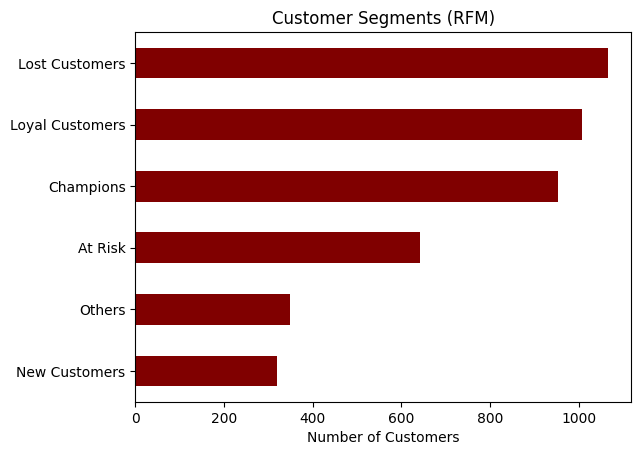

In [66]:
def segment_customer(row):
    r, f, m = int(row['R_Score']), int(row['F_Score']), int(row['M_Score'])
    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'
    elif r >= 3 and f >= 3:
        return 'Loyal Customers'
    elif r >= 4 and f <= 2:
        return 'New Customers'
    elif r <= 2 and f >= 3:
        return 'At Risk'
    elif r <= 2 and f <= 2:
        return 'Lost Customers'
    else:
        return 'Others'

rfm['Segment'] = rfm.apply(segment_customer, axis=1)

rfm['Segment'].value_counts().sort_values().plot(kind='barh', color='maroon')
plt.title('Customer Segments (RFM)')
plt.xlabel('Number of Customers')
plt.ylabel('')
plt.show()

### Adding Customer Segments to Transactions

Merge the customer-level RFM segment information back into the transaction data so that each transaction can be analyzed by customer segment.

In [67]:
df = df.merge(rfm[['Segment']], on='CustomerID', how='left')

### Revenue Contribution by Customer Segment

Compare the revenue generated by each customer segment based on completed purchase transactions.

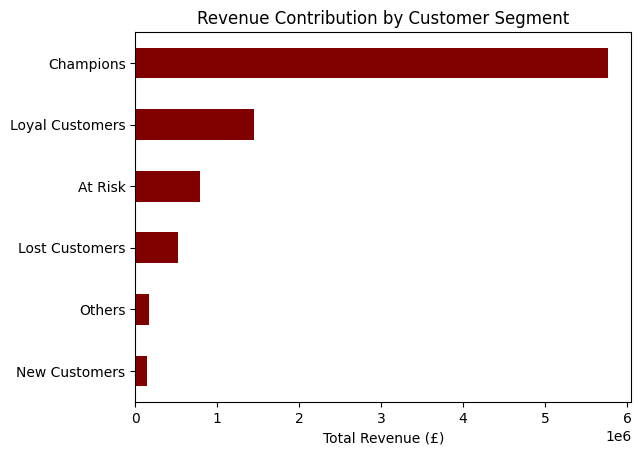

Segment
Champions          5765056.430
Loyal Customers    1452921.891
At Risk             790337.782
Lost Customers      516434.521
Others              162968.430
New Customers       146069.910
Name: Total Cost, dtype: float64


In [68]:
segment_revenue = df[df['Quantity'] > 0].groupby('Segment')['Total Cost'].sum().sort_values(ascending=False)

segment_revenue.plot(kind='barh', color='maroon')
plt.gca().invert_yaxis()
plt.title('Revenue Contribution by Customer Segment')
plt.xlabel('Total Revenue (£)')
plt.ylabel('')
plt.show()

print(segment_revenue)

### Top Products Purchased by Champions

Identify the five products with the highest total quantity purchased by customers in the Champions segment.

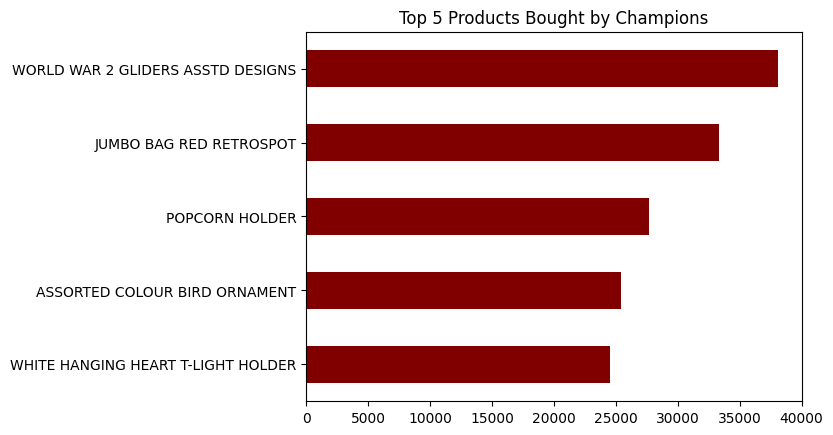

In [69]:
top_products_champions = df[(df['Segment'] == 'Champions') & (df['Quantity'] > 0)].groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(5)
top_products_champions.plot(kind='barh', color='maroon')
plt.gca().invert_yaxis()
plt.title('Top 5 Products Bought by Champions')
plt.ylabel('')
plt.show()

### Key Insight: Revenue Concentration

Champions generated the highest purchase revenue among the customer segments, indicating a high contribution from recently active, frequent, and high-value customers.

This highlights the importance of understanding the purchasing behaviour of high-value customers. The At Risk and Lost Customers segments can also be examined to understand declining customer activity and cancellation behaviour.

___

## Customer Purchase Frequency Analysis

Analyze customers based on their purchase frequency, focusing first on one-time customers and then on repeat customers.

### One-time customers v/s repeat customers

In [70]:
customerCount = df[df['Quantity'] > 0].groupby('CustomerID')['InvoiceNo'].nunique()

# one-time customers
oneTimecustomer = customerCount[customerCount == 1]  
oneTimecustomerdf = df[df['CustomerID'].isin(oneTimecustomer.index)].copy()

# repeat customers
repeatCustomers  = customerCount[customerCount > 1]
repeatCustomersdf = df[df['CustomerID'].isin(repeatCustomers.index)].copy()

In [71]:
print(f"One-time customers: {len(oneTimecustomer)}")
print(f"Repeat customers: {len(repeatCustomers)}")

One-time customers: 1496
Repeat customers: 2839


In [72]:
# Customer count
oneTimeCustomerCount = len(oneTimecustomer)
repeatCustomerCount = len(repeatCustomers)

# Purchase revenue
oneTimeRevenue = oneTimecustomerdf[oneTimecustomerdf['Quantity'] > 0]['Total Cost'].sum()
repeatRevenue = repeatCustomersdf[repeatCustomersdf['Quantity'] > 0]['Total Cost'].sum()

# Average revenue
oneTimeAverageRevenue = oneTimeRevenue / oneTimeCustomerCount
repeatAverageRevenue = repeatRevenue / repeatCustomerCount

# Cancellation value
oneTimeCancellationValue = oneTimecustomerdf[oneTimecustomerdf['Quantity'] < 0]['Total Cost'].sum()
repeatCancellationValue = repeatCustomersdf[repeatCustomersdf['Quantity'] < 0]['Total Cost'].sum()

In [73]:
customerComparison = pd.DataFrame({
    'One-Time Customers': [
        oneTimeCustomerCount,
        oneTimeRevenue,
        oneTimeCancellationValue,
        oneTimeAverageRevenue
    ],
    'Repeat Customers': [
        repeatCustomerCount,
        repeatRevenue,
        repeatCancellationValue,
        repeatAverageRevenue
    ]
}, index=[
    'Customer Count',
    'Purchase Revenue',
    'Cancellation Value',
    'Average Purchase Revenue'
])

customerComparison.style.format('{:,.2f}')

,One-Time Customers,Repeat Customers
Customer Count,"1,496.00","2,839.00"
Purchase Revenue,"619,091.00","8,214,697.96"
Cancellation Value,"-91,195.27","-396,521.47"
Average Purchase Revenue,413.83,"2,893.52"


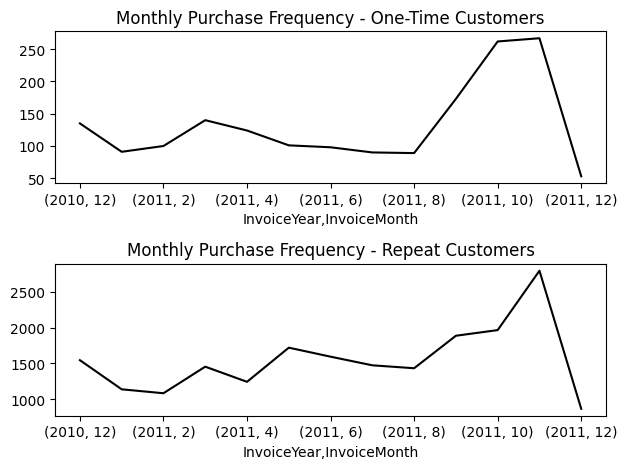

In [74]:
# Purchase Frequency Comparison
oneTimePurchaseFrequency = oneTimecustomerdf.groupby(['InvoiceYear', 'InvoiceMonth'])['InvoiceNo'].nunique()
repeatPurchaseFrequency = repeatCustomersdf.groupby(['InvoiceYear', 'InvoiceMonth'])['InvoiceNo'].nunique()

fig, ax = plt.subplots(2, 1)

oneTimePurchaseFrequency.plot(kind='line', color='black', ax=ax[0])
repeatPurchaseFrequency.plot(kind='line', color='black', ax=ax[1])

ax[0].set_title('Monthly Purchase Frequency - One-Time Customers')
ax[1].set_title('Monthly Purchase Frequency - Repeat Customers')

fig.tight_layout()

**Insight:** Purchase activity was highest among one-time customers in October-November 2011
and among repeat customers during November 2011.

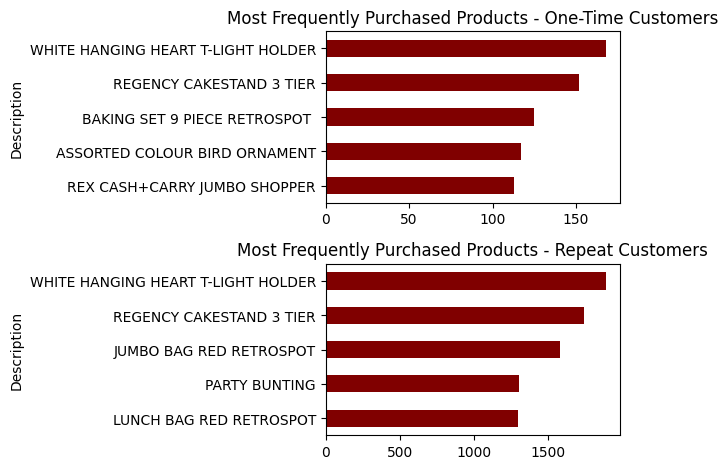

In [75]:
# Most Frequently Purchased Products Comparison
oneTimeTopProducts  = oneTimecustomerdf.groupby('Description')['Description'].agg('count').sort_values(ascending=False).head(5)
repeatTopProducts = repeatCustomersdf.groupby('Description')['Description'].agg('count').sort_values(ascending=False).head(5)

fig, ax = plt.subplots(2, 1)

oneTimeTopProducts.plot(kind='barh', color='maroon', ax=ax[0])
repeatTopProducts.plot(kind='barh', color='maroon', ax=ax[1])

ax[0].set_title('Most Frequently Purchased Products - One-Time Customers')
ax[1].set_title('Most Frequently Purchased Products - Repeat Customers')

ax[0].invert_yaxis()
ax[1].invert_yaxis()

fig.tight_layout()

___

## Cancellation Behaviour Analysis

Analyze when cancellations occur most frequently and which products are most commonly cancelled.

### Identifying Cancelled Transactions

Filter transactions with negative quantities to isolate cancelled products.

In [76]:
cancellationdf = df[df['Quantity'] < 0].copy()
cancellationdf = cancellationdf.reset_index(drop=True)
cancellationdf.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvoiceDay,InvoiceMonth,InvoiceYear,Total Cost,Segment
0,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311,United Kingdom,1,12,2010,-4.65,Champions
1,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548,United Kingdom,1,12,2010,-19.80,Lost Customers
2,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom,1,12,2010,-6.96,Lost Customers
3,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom,1,12,2010,-6.96,Lost Customers
4,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom,1,12,2010,-6.96,Lost Customers


### Monthly Cancellation Trend

In [77]:
cancellationTrend = cancellationdf.groupby(['InvoiceYear', 'InvoiceMonth'])['InvoiceNo'].nunique()
cancellationTrend

InvoiceYear  InvoiceMonth
2010         12              300
2011         1               244
             2               191
             3               279
             4               223
             5               272
             6               300
             7               237
             8               243
             9               309
             10              315
             11              413
             12              139
Name: InvoiceNo, dtype: int64

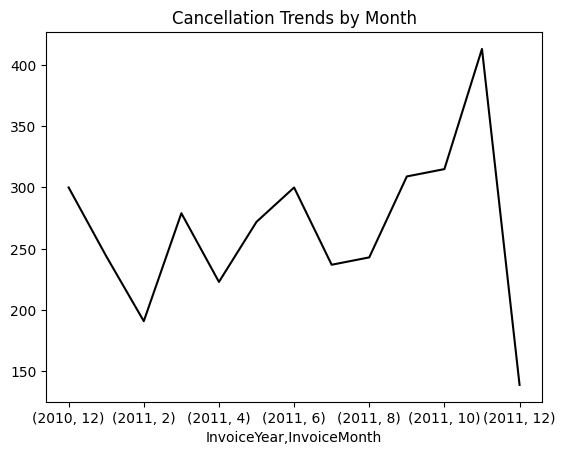

In [78]:
cancellationTrend.plot(kind='line', color='black')
plt.title('Cancellation Trends by Month')
plt.show()

**Insight:** Cancellation activity was highest toward the end of 2011.

### Peak Cancellation Period

In [79]:
peakCancellation = cancellationdf[(cancellationdf['InvoiceMonth'] == 11) & (cancellationdf['InvoiceYear'] == 2011)]
peakCancellation.sample(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvoiceDay,InvoiceMonth,InvoiceYear,Total Cost,Segment
7767,C576561,22845,VINTAGE CREAM CAT FOOD CONTAINER,-1,2011-11-15 13:22:00,5.55,15311,United Kingdom,15,11,2011,-5.55,Champions
8001,C577889,22248,DECORATION PINK CHICK MAGIC GARDEN,-16,2011-11-22 11:42:00,0.85,16191,United Kingdom,22,11,2011,-13.60,Champions
7354,C574350,23225,CHERUB HEART DECORATION SILVER,-12,2011-11-04 10:36:00,0.83,16637,United Kingdom,4,11,2011,-9.96,Champions
8037,C578142,23569,TRADTIONAL ALPHABET STAMP SET,-2,2011-11-23 11:04:00,4.95,17010,United Kingdom,23,11,2011,-9.90,New Customers
8228,C579785,22845,VINTAGE CREAM CAT FOOD CONTAINER,-3,2011-11-30 15:29:00,6.35,12584,Italy,30,11,2011,-19.05,Champions


### Most Cancelled Products During the Peak Cancellation Period

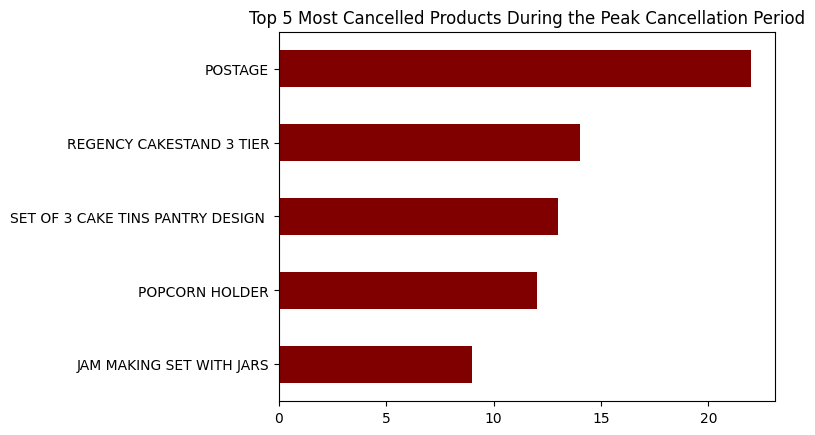

In [80]:
peakCancellation['Description'].value_counts().head(5).plot(kind='barh', color='maroon')
plt.gca().invert_yaxis()
plt.title('Top 5 Most Cancelled Products During the Peak Cancellation Period')
plt.ylabel('')
plt.show()

### Countries with the Most Cancellations

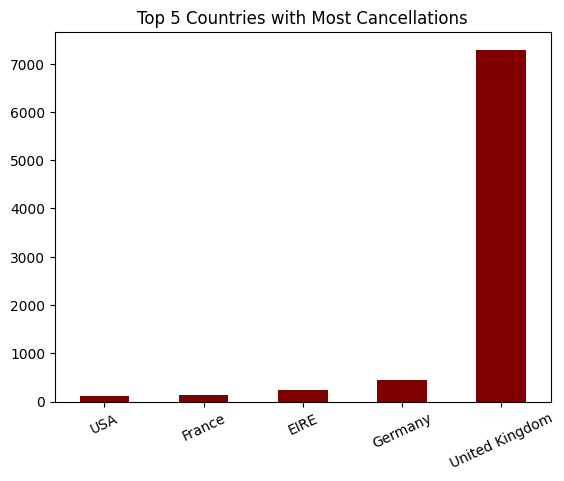

In [81]:
cancellationdf.groupby('Country')['CustomerID'].agg('count').sort_values().tail(5).plot(kind='bar', color='maroon')
plt.xticks(rotation=25)
plt.xlabel('')
plt.title('Top 5 Countries with Most Cancellations')
plt.show()

### Total Value of Cancelled Products

In [82]:
TotalCancelledValue = cancellationdf['Total Cost'].sum()
print(f'Total cancellation value is {TotalCancelledValue}')

Total cancellation value is -490827.8600000001


### Transactions Without Cancellations

In [83]:
PurchaseTransactionsdf = df[df['Quantity'] > 0].copy()
PurchaseTransactionsdf = PurchaseTransactionsdf.reset_index(drop=True)
PurchaseTransactionsdf.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvoiceDay,InvoiceMonth,InvoiceYear,Total Cost,Segment
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,1,12,2010,15.30,At Risk
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,1,12,2010,20.34,At Risk
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,1,12,2010,22.00,At Risk
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,1,12,2010,20.34,At Risk
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,1,12,2010,20.34,At Risk


### Total Purchase Revenue

In [84]:
TotalPurchaseRevenue = PurchaseTransactionsdf['Total Cost'].sum()
print(f'Total revenue by purchases is {TotalPurchaseRevenue}')

Total revenue by purchases is 8833788.964000002


___

## Final Insights

### Customer Segmentation

* **Champions generated £5.77M**, accounting for approximately **65.3% of total purchase revenue (£8.83M)**, making them the largest revenue-contributing customer segment.
* Loyal Customers generated **£1.45M**, followed by At Risk customers at **£790.34K** and Lost Customers at **£516.43K**.
* The results show that recently active, frequent, and high-value customers contributed a substantial share of the retailer's purchase revenue.

### One-Time vs Repeat Customers

* There were **1,496 one-time customers** and **2,839 repeat customers** in the analysis.
* Repeat customers generated **£8.21M** in purchase revenue compared with **£619.09K** from one-time customers.
* Repeat customers therefore contributed approximately **93.0% of total purchase revenue**, while one-time customers contributed approximately **7.0%**.
* Average purchase revenue was **£2,893.52 per repeat customer**, compared with **£413.83 per one-time customer**.
* Purchase activity was highest among one-time customers during **October–November 2011**, while repeat-customer purchase activity peaked in **November 2011**.

### Cancellation Behaviour

* The total value of cancellation records was **-£490.83K**, compared with **£8.83M in purchase revenue**.
* Repeat customers accounted for **-£396.52K** of cancellation value, while one-time customers accounted for **-£91.20K**.
* Approximately **80.8% of the total cancellation value** came from repeat customers, while one-time customers accounted for approximately **18.6%**. The remaining difference is due to the customer grouping and transaction data used in the comparison.
* Cancellation activity was highest toward the **end of 2011**, with **November 2011** identified as the peak cancellation period.
* The product and country-level analyses identify areas where frequently occurring cancellation records can be investigated further.

### Overall Conclusion

The analysis shows that purchase revenue was strongly concentrated among **high-value and repeat customers**. Champions generated **£5.77M (65.3%)** of the **£8.83M** total purchase revenue, while repeat customers generated **£8.21M (93.0%)**.

Cancellation activity was also substantial, with cancellation records representing **-£490.83K** in transaction value. Repeat customers accounted for the majority of this cancellation value, and cancellation activity increased toward the end of 2011, peaking in **November 2011**.

These findings highlight several areas for further investigation, including **high-value customer behaviour, customer retention, frequently cancelled products, and periods with elevated cancellation activity**.
